# Step 1 — Setup and data loading


In [25]:
# Install the required packages

%pip install -q langchain-text-splitters pypdf openai tiktoken sentence-transformers matplotlib pandas python-dotenv

Note: you may need to restart the kernel to use updated packages.


In [26]:
import os, re, json, statistics
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from pypdf import PdfReader

from langchain_text_splitters import (
    CharacterTextSplitter,
    RecursiveCharacterTextSplitter,
    TokenTextSplitter,
)

In [27]:
# Load environment variables for API keys
load_dotenv()   # reads the .env file

if os.getenv("OPENAI_API_KEY"):
    print("API key found")
else:
    print("No API key found. Check your .env file (it is needed for transcription).")

API key found


In [28]:
# Load the podcast audio file
AUDIO_PATH = Path("The_Blueprint_For_Trustworthy_AI.m4a")

print("Current working folder:", Path.cwd())
if AUDIO_PATH.exists():
    print(f"Audio found: {AUDIO_PATH.name} ({AUDIO_PATH.stat().st_size / 1_000_000:.1f} MB)")
else:
    print("Audio NOT FOUND. Move the file into the folder shown above.")

Current working folder: c:\Users\antun\ai-project\W3\Day-2\lab-chunking-strategies
Audio found: The_Blueprint_For_Trustworthy_AI.m4a (30.2 MB)


In [29]:
# Transcribe the audio file (save it to a local file)
import subprocess, glob

TRANSCRIPT_PATH = Path("transcript.txt")

def transcribe_audio(audio_path, out_path, model="whisper-1", piece_seconds=600):
    """Transcribe audio with the OpenAI API and save the text. Skips all work if out_path already exists."""
    out = Path(out_path)
    if out.exists() and out.stat().st_size > 0:
        print(f"{out} already exists -> skipping transcription")
        return out.read_text(encoding="utf-8")

    # 1) shrink and cut the audio: mono, 64 kbps mp3, 10-minute pieces
    Path("_pieces").mkdir(exist_ok=True)
    subprocess.run(["ffmpeg", "-v", "error", "-y", "-i", str(audio_path), "-ac", "1", "-b:a", "64k",
                    "-f", "segment", "-segment_time", str(piece_seconds), "-reset_timestamps", "1",
                    "_pieces/piece_%02d.mp3"], check=True)

    # 2) transcribe the pieces in order
    from openai import OpenAI
    client = OpenAI()                                  # uses OPENAI_API_KEY from the environment
    texts = []
    for f in sorted(glob.glob("_pieces/piece_*.mp3")):
        with open(f, "rb") as fh:
            texts.append(client.audio.transcriptions.create(model=model, file=fh).text)
        print(f, "done")

    text = " ".join(texts)
    out.write_text(text, encoding="utf-8")             # save to a local file
    return text

podcast_text = transcribe_audio(AUDIO_PATH, TRANSCRIPT_PATH)
print(f"Podcast transcript length: {len(podcast_text)} chars")
print(podcast_text[:200])


transcript.txt already exists -> skipping transcription
Podcast transcript length: 16313 chars
So imagine for a second you're driving across I don't know a massive suspension bridge. OK. You don't pull over halfway across get out and demand to see the blueprints. Right. You don't interview the 


In [30]:
# Load the PDF document (from a URL or a local file)
PDF_PATH = Path("ai_hleg_ethics_guidelines_for_trustworthy_ai-en_87F84A41-A6E8-F38C-BFF661481B40077B_60419.pdf")

def load_pdf(path=PDF_PATH):
    reader = PdfReader(path)
    return "\n".join(page.extract_text() or "" for page in reader.pages)

pdf_text = load_pdf()
print(f"PDF length: {len(pdf_text)} chars")
print(pdf_text[:200])


PDF length: 156411 chars
 
 
 
 
 
 
INDEPENDENT 
HIGH-LEVEL EXPERT GROUP ON 
ARTIFICIAL INTELLIGENCE 
SET UP BY THE EUROPEAN COMMISSION 
 
 
 
 
 
 
ETHICS GUIDELINES 
FOR TRUSTWORTHY AI 
 
 
 
 
 
 
ETHICS GUIDELINES FOR TR


# Step 2: Implement Fixed-Size Chunking

### PDF

#### Experiment with different sizes: 500, 1000, 2000 characters

##### Chunk size 500 / overlap=50

In [31]:
splitter = CharacterTextSplitter(separator="", chunk_size=500, chunk_overlap=50) # separator="" for fixed-size (default: separator="\n\n")
pdf_text = load_pdf()
print(f"PDF length: {len(pdf_text)} chars")
print(f"Total chunks created: {len(chunks)}")
print("\n" + "✂️Chunk[0] size 500" + "\n" + "="*50)
chunks = splitter.split_text(pdf_text)
print(chunks[0])



PDF length: 156411 chars


NameError: name 'chunks' is not defined

In [ ]:
print("\n" + "✂️Chunk[1] size 500" + "\n" + "="*50)
chunks = splitter.split_text(pdf_text)
print(chunks[1])


✂️Chunk[1] size 500
e opinion of the AI HLEG and may not in any circumstances be 
regarded as reflecting an official position of the European Commission.  
 
More information on the High -Level Expert Group on Artificial Intelligence is available online (https://ec.europa.eu/digital-
single-market/en/high-level-expert-group-artificial-intelligence).  
The reuse policy of European Commission documents is regulated by Decision 2011/8 33/EU (OJ L 330, 14. 12.2011, p.39). 
For any use or reproduction of photos or other material that is not under the EU copyright, permission must be sought 
directly from the copyright holders.  
1 
 
 
 
TABLE OF CONTENTS 
 
 
EXECUTIVE SUMMARY 2 
A. INTRODUCTION 4 
B. A FRAMEWORK FOR TRUSTWORTHY AI 6 
I. Chapter I: Foundations of Trustworthy AI 9 
II. Chapter II: Realising Trustworthy AI   14 
1.    Requirements of Trustworthy AI                        14 
2.    Technical and non-technical methods to realise Trustworthy AI                   22 
III. Chapt

In [ ]:
print("\n" + "✂️Chunk[2] size 500" + "\n" + "="*50)
chunks = splitter.split_text(pdf_text)
print(chunks[2])


✂️Chunk[2] size 500
thy AI. The framework  does not explicitly deal with 
Trustworthy AI’s first component ( lawful AI). 1 Instead, it aims to offer guidance on the second and third 
components: fostering and securing ethical and robust AI. Addressed to all stakeholders, these Guidelines seek to go 
beyond a list of ethical principles, by providing guidance on how such principles can be operationalised in socio -
technical systems. Guidance is provided in three layers of abstraction, fr om the most abstract in Chapter I to the 
most concrete in Chapter III, closing with examples of opportunities and critical concerns raised by AI systems. 
I. Based on an approach founded on fundamental rights, Chapter I identifies the ethical principles and their 
correlated values that must be respected in the development, deployment and use of AI systems.  
Key guidance derived from Chapter I: 
 Develop, deploy and use AI systems  in a way that adhere s to the ethical principles of : respect for h 

##### Chunk size 1000 / overlap=50

In [ ]:
# Experiment with different sizes: 500, 1000, 2000 characters
splitter = CharacterTextSplitter(separator="", chunk_size=1000, chunk_overlap=50)
pdf_text = load_pdf()
print(f"PDF length: {len(pdf_text)} chars")
print(f"Total chunks created: {len(chunks)}")

print("\n" + "✂️Chunk[0] size 1000" + "\n" + "="*50)
chunks = splitter.split_text(pdf_text)
print(chunks[0])




PDF length: 156411 chars
Total chunks created: 348

✂️Chunk[0] size 1000
INDEPENDENT 
HIGH-LEVEL EXPERT GROUP ON 
ARTIFICIAL INTELLIGENCE 
SET UP BY THE EUROPEAN COMMISSION 
 
 
 
 
 
 
ETHICS GUIDELINES 
FOR TRUSTWORTHY AI 
 
 
 
 
 
 
ETHICS GUIDELINES FOR TRUSTWORTHY AI 
 
High-Level Expert Group on Artificial Intelligence 
 
 
 
 
 
 
 
 
This document was written by the High-Level Expert Group on AI (AI HLEG) . The members of the AI HLEG 
named in this document support the overall framework for Trustworthy AI put forward in these Guidelines, 
although they do not necessarily agree with every single statement in the document .  
 
The Trustworthy AI assessment list presented in Chapter III of this document will undergo a piloting phase by 
stakeholders to gather practical feedback. A revised version  of the assessment list, taking into account the 
feedback gathered through the piloting phase, will be presented to the Eu ropean Commission in early 2020. 
 
 
The AI HLEG is an indep

In [ ]:
print("\n" + "✂️Chunk[1] size 1000" + "\n" + "="*50)
chunks = splitter.split_text(pdf_text)
print(chunks[1])


✂️Chunk[1] size 1000
e opinion of the AI HLEG and may not in any circumstances be 
regarded as reflecting an official position of the European Commission.  
 
More information on the High -Level Expert Group on Artificial Intelligence is available online (https://ec.europa.eu/digital-
single-market/en/high-level-expert-group-artificial-intelligence).  
The reuse policy of European Commission documents is regulated by Decision 2011/8 33/EU (OJ L 330, 14. 12.2011, p.39). 
For any use or reproduction of photos or other material that is not under the EU copyright, permission must be sought 
directly from the copyright holders.  
1 
 
 
 
TABLE OF CONTENTS 
 
 
EXECUTIVE SUMMARY 2 
A. INTRODUCTION 4 
B. A FRAMEWORK FOR TRUSTWORTHY AI 6 
I. Chapter I: Foundations of Trustworthy AI 9 
II. Chapter II: Realising Trustworthy AI   14 
1.    Requirements of Trustworthy AI                        14 
2.    Technical and non-technical methods to realise Trustworthy AI                   22 
III. Chap

In [ ]:
print("\n" + "✂️Chunk[2] size 1000" + "\n" + "="*50)
chunks = splitter.split_text(pdf_text)
print(chunks[2])


✂️Chunk[2] size 1000
thy AI. The framework  does not explicitly deal with 
Trustworthy AI’s first component ( lawful AI). 1 Instead, it aims to offer guidance on the second and third 
components: fostering and securing ethical and robust AI. Addressed to all stakeholders, these Guidelines seek to go 
beyond a list of ethical principles, by providing guidance on how such principles can be operationalised in socio -
technical systems. Guidance is provided in three layers of abstraction, fr om the most abstract in Chapter I to the 
most concrete in Chapter III, closing with examples of opportunities and critical concerns raised by AI systems. 
I. Based on an approach founded on fundamental rights, Chapter I identifies the ethical principles and their 
correlated values that must be respected in the development, deployment and use of AI systems.  
Key guidance derived from Chapter I: 
 Develop, deploy and use AI systems  in a way that adhere s to the ethical principles of : respect for h

##### Chunk size 2000 / overlap=50


In [ ]:
# Experiment with different sizes: 500, 1000, 2000 characters
splitter = CharacterTextSplitter(separator="", chunk_size=2000, chunk_overlap=50)
pdf_text = load_pdf()
print(f"PDF length: {len(pdf_text)} chars")
print(f"Total chunks created: {len(chunks)}")

print("\n" + "✂️Chunk[0] size 2000" + "\n" + "="*50)
chunks = splitter.split_text(pdf_text)
print(chunks[0])


PDF length: 156411 chars
Total chunks created: 165

✂️Chunk[0] size 2000
INDEPENDENT 
HIGH-LEVEL EXPERT GROUP ON 
ARTIFICIAL INTELLIGENCE 
SET UP BY THE EUROPEAN COMMISSION 
 
 
 
 
 
 
ETHICS GUIDELINES 
FOR TRUSTWORTHY AI 
 
 
 
 
 
 
ETHICS GUIDELINES FOR TRUSTWORTHY AI 
 
High-Level Expert Group on Artificial Intelligence 
 
 
 
 
 
 
 
 
This document was written by the High-Level Expert Group on AI (AI HLEG) . The members of the AI HLEG 
named in this document support the overall framework for Trustworthy AI put forward in these Guidelines, 
although they do not necessarily agree with every single statement in the document .  
 
The Trustworthy AI assessment list presented in Chapter III of this document will undergo a piloting phase by 
stakeholders to gather practical feedback. A revised version  of the assessment list, taking into account the 
feedback gathered through the piloting phase, will be presented to the Eu ropean Commission in early 2020. 
 
 
The AI HLEG is an indep

In [ ]:
print("\n" + "✂️Chunk[1] size 2000" + "\n" + "="*50)
chunks = splitter.split_text(pdf_text)
print(chunks[1])


✂️Chunk[1] size 2000
e opinion of the AI HLEG and may not in any circumstances be 
regarded as reflecting an official position of the European Commission.  
 
More information on the High -Level Expert Group on Artificial Intelligence is available online (https://ec.europa.eu/digital-
single-market/en/high-level-expert-group-artificial-intelligence).  
The reuse policy of European Commission documents is regulated by Decision 2011/8 33/EU (OJ L 330, 14. 12.2011, p.39). 
For any use or reproduction of photos or other material that is not under the EU copyright, permission must be sought 
directly from the copyright holders.  
1 
 
 
 
TABLE OF CONTENTS 
 
 
EXECUTIVE SUMMARY 2 
A. INTRODUCTION 4 
B. A FRAMEWORK FOR TRUSTWORTHY AI 6 
I. Chapter I: Foundations of Trustworthy AI 9 
II. Chapter II: Realising Trustworthy AI   14 
1.    Requirements of Trustworthy AI                        14 
2.    Technical and non-technical methods to realise Trustworthy AI                   22 
III. Chap

In [ ]:
print("\n" + "✂️Chunk[2] size 2000" + "\n" + "="*50)
chunks = splitter.split_text(pdf_text)
print(chunks[2])


✂️Chunk[2] size 2000
thy AI. The framework  does not explicitly deal with 
Trustworthy AI’s first component ( lawful AI). 1 Instead, it aims to offer guidance on the second and third 
components: fostering and securing ethical and robust AI. Addressed to all stakeholders, these Guidelines seek to go 
beyond a list of ethical principles, by providing guidance on how such principles can be operationalised in socio -
technical systems. Guidance is provided in three layers of abstraction, fr om the most abstract in Chapter I to the 
most concrete in Chapter III, closing with examples of opportunities and critical concerns raised by AI systems. 
I. Based on an approach founded on fundamental rights, Chapter I identifies the ethical principles and their 
correlated values that must be respected in the development, deployment and use of AI systems.  
Key guidance derived from Chapter I: 
 Develop, deploy and use AI systems  in a way that adhere s to the ethical principles of : respect for h

#### Try different overlap values: 0 and 100 characters

##### Chunk size 500 / overlap=0

In [ ]:
splitter = CharacterTextSplitter(separator="", chunk_size=500, chunk_overlap=0)
pdf_text = load_pdf()
print(f"PDF length: {len(pdf_text)} chars")

print("\n" + "✂️Chunk[0] size 500 with overlap=0" + "\n" + "="*50)
chunks = splitter.split_text(pdf_text)
print(chunks[0])

PDF length: 156411 chars

✂️Chunk[0] size 500 with overlap=0
INDEPENDENT 
HIGH-LEVEL EXPERT GROUP ON 
ARTIFICIAL INTELLIGENCE 
SET UP BY THE EUROPEAN COMMISSION 
 
 
 
 
 
 
ETHICS GUIDELINES 
FOR TRUSTWORTHY AI 
 
 
 
 
 
 
ETHICS GUIDELINES FOR TRUSTWORTHY AI 
 
High-Level Expert Group on Artificial Intelligence 
 
 
 
 
 
 
 
 
This document was written by the High-Level Expert Group on AI (AI HLEG) . The members of the AI HLEG 
named in this document support the overall framework for Trustworthy AI put forward in these Guidelines, 
althoug


In [ ]:
print("\n" + "✂️Chunk[1] size 500 with overlap=0" + "\n" + "="*50)
chunks = splitter.split_text(pdf_text)
print(chunks[1])


✂️Chunk[1] size 500 with overlap=0
h they do not necessarily agree with every single statement in the document .  
 
The Trustworthy AI assessment list presented in Chapter III of this document will undergo a piloting phase by 
stakeholders to gather practical feedback. A revised version  of the assessment list, taking into account the 
feedback gathered through the piloting phase, will be presented to the Eu ropean Commission in early 2020. 
 
 
The AI HLEG is an independent expert group that was set up by the European Commissio


In [ ]:
print("\n" + "✂️Chunk[2] size 500 with overlap=0" + "\n" + "="*50)
chunks = splitter.split_text(pdf_text)
print(chunks[2])



✂️Chunk[2] size 500 with overlap=0
n in June 2018.  
 
Contact  Nathalie Smuha - AI HLEG Coordinator  
E-mail  CNECT-HLG-AI@ec.europa.eu  
 
European Commission  
B-1049 Brussels  
 
Document made public on 8 April 2019.  
 
A first draft of this document was released on 18 December 2018 and was subject to an open consultation which 
generated feedback from more than 500 contributors. We wish to explicitly and warmly thank all those who contributed 
their feedback on the document's first draft, which was considered in the prepara


##### Chunk size 500 / overlap=100

In [ ]:
# Try different overlap values: 0, 50, 100 characters
splitter = CharacterTextSplitter(separator="", chunk_size=500, chunk_overlap=100)
pdf_text = load_pdf()
print(f"PDF length: {len(pdf_text)} chars")

print("\n" + "✂️Chunk[0] size 500 with overlap=100" + "\n" + "="*50)
chunks = splitter.split_text(pdf_text)
print(chunks[0])

PDF length: 156411 chars

✂️Chunk[0] size 500 with overlap=100
INDEPENDENT 
HIGH-LEVEL EXPERT GROUP ON 
ARTIFICIAL INTELLIGENCE 
SET UP BY THE EUROPEAN COMMISSION 
 
 
 
 
 
 
ETHICS GUIDELINES 
FOR TRUSTWORTHY AI 
 
 
 
 
 
 
ETHICS GUIDELINES FOR TRUSTWORTHY AI 
 
High-Level Expert Group on Artificial Intelligence 
 
 
 
 
 
 
 
 
This document was written by the High-Level Expert Group on AI (AI HLEG) . The members of the AI HLEG 
named in this document support the overall framework for Trustworthy AI put forward in these Guidelines, 
althoug


In [ ]:
print("\n" + "✂️Chunk[1] size 500 with overlap=100" + "\n" + "="*50)
chunks = splitter.split_text(pdf_text)
print(chunks[1])


✂️Chunk[1] size 500 with overlap=100
document support the overall framework for Trustworthy AI put forward in these Guidelines, 
although they do not necessarily agree with every single statement in the document .  
 
The Trustworthy AI assessment list presented in Chapter III of this document will undergo a piloting phase by 
stakeholders to gather practical feedback. A revised version  of the assessment list, taking into account the 
feedback gathered through the piloting phase, will be presented to the Eu ropean Commission in e


In [ ]:
print("\n" + "✂️Chunk[2] size 500 with overlap=100" + "\n" + "="*50)
chunks = splitter.split_text(pdf_text)
print(chunks[2])


✂️Chunk[2] size 500 with overlap=100
he 
feedback gathered through the piloting phase, will be presented to the Eu ropean Commission in early 2020. 
 
 
The AI HLEG is an independent expert group that was set up by the European Commission in June 2018.  
 
Contact  Nathalie Smuha - AI HLEG Coordinator  
E-mail  CNECT-HLG-AI@ec.europa.eu  
 
European Commission  
B-1049 Brussels  
 
Document made public on 8 April 2019.  
 
A first draft of this document was released on 18 December 2018 and was subject to an open consultation which


##### Chunk size 1000 / overlap=0

In [ ]:
# Try different overlap values: 0, 50, 100 characters
splitter = CharacterTextSplitter(separator="", chunk_size=1000, chunk_overlap=0)
pdf_text = load_pdf()
print(f"PDF length: {len(pdf_text)} chars")

print("\n" + "✂️Chunk[0] size 1000 with overlap=0" + "\n" + "="*50)
chunks = splitter.split_text(pdf_text)
print(chunks[0])

PDF length: 156411 chars

✂️Chunk[0] size 1000 with overlap=0
INDEPENDENT 
HIGH-LEVEL EXPERT GROUP ON 
ARTIFICIAL INTELLIGENCE 
SET UP BY THE EUROPEAN COMMISSION 
 
 
 
 
 
 
ETHICS GUIDELINES 
FOR TRUSTWORTHY AI 
 
 
 
 
 
 
ETHICS GUIDELINES FOR TRUSTWORTHY AI 
 
High-Level Expert Group on Artificial Intelligence 
 
 
 
 
 
 
 
 
This document was written by the High-Level Expert Group on AI (AI HLEG) . The members of the AI HLEG 
named in this document support the overall framework for Trustworthy AI put forward in these Guidelines, 
although they do not necessarily agree with every single statement in the document .  
 
The Trustworthy AI assessment list presented in Chapter III of this document will undergo a piloting phase by 
stakeholders to gather practical feedback. A revised version  of the assessment list, taking into account the 
feedback gathered through the piloting phase, will be presented to the Eu ropean Commission in early 2020. 
 
 
The AI HLEG is an independent expe

In [ ]:
print("\n" + "✂️Chunk[1] size 1000 with overlap=0" + "\n" + "="*50)
chunks = splitter.split_text(pdf_text)
print(chunks[1])


✂️Chunk[1] size 1000 with overlap=0
n in June 2018.  
 
Contact  Nathalie Smuha - AI HLEG Coordinator  
E-mail  CNECT-HLG-AI@ec.europa.eu  
 
European Commission  
B-1049 Brussels  
 
Document made public on 8 April 2019.  
 
A first draft of this document was released on 18 December 2018 and was subject to an open consultation which 
generated feedback from more than 500 contributors. We wish to explicitly and warmly thank all those who contributed 
their feedback on the document's first draft, which was considered in the preparation of this revised version. 
 
Neither the European Commission nor any person acting on behalf of the Commission is responsible for the use which 
might be made of the following information. The contents of this working document are the sole responsibility of the High-
Level Expert Group on Artificial Intelligence (AI HLEG). Although Commission staff facilitated the preparation of the 
Guidelines, the views expressed in this document reflect the opinion of 

In [ ]:
print("\n" + "✂️Chunk[2] size 1000 with overlap=0" + "\n" + "="*50)
chunks = splitter.split_text(pdf_text)
print(chunks[2])


✂️Chunk[2] size 1000 with overlap=0
stances be 
regarded as reflecting an official position of the European Commission.  
 
More information on the High -Level Expert Group on Artificial Intelligence is available online (https://ec.europa.eu/digital-
single-market/en/high-level-expert-group-artificial-intelligence).  
The reuse policy of European Commission documents is regulated by Decision 2011/8 33/EU (OJ L 330, 14. 12.2011, p.39). 
For any use or reproduction of photos or other material that is not under the EU copyright, permission must be sought 
directly from the copyright holders.  
1 
 
 
 
TABLE OF CONTENTS 
 
 
EXECUTIVE SUMMARY 2 
A. INTRODUCTION 4 
B. A FRAMEWORK FOR TRUSTWORTHY AI 6 
I. Chapter I: Foundations of Trustworthy AI 9 
II. Chapter II: Realising Trustworthy AI   14 
1.    Requirements of Trustworthy AI                        14 
2.    Technical and non-technical methods to realise Trustworthy AI                   22 
III. Chapter III: Assessing Trustworthy AI 2

##### Chunk size 1000 / overlap=100

In [ ]:
# Try different overlap values: 0, 50, 100 characters
splitter = CharacterTextSplitter(separator="", chunk_size=1000, chunk_overlap=100)
pdf_text = load_pdf()
print(f"PDF length: {len(pdf_text)} chars")

print("\n" + "✂️Chunk[0] size 1000 with overlap=100" + "\n" + "="*50)
chunks = splitter.split_text(pdf_text)
print(chunks[0])

PDF length: 156411 chars

✂️Chunk[0] size 1000 with overlap=100
INDEPENDENT 
HIGH-LEVEL EXPERT GROUP ON 
ARTIFICIAL INTELLIGENCE 
SET UP BY THE EUROPEAN COMMISSION 
 
 
 
 
 
 
ETHICS GUIDELINES 
FOR TRUSTWORTHY AI 
 
 
 
 
 
 
ETHICS GUIDELINES FOR TRUSTWORTHY AI 
 
High-Level Expert Group on Artificial Intelligence 
 
 
 
 
 
 
 
 
This document was written by the High-Level Expert Group on AI (AI HLEG) . The members of the AI HLEG 
named in this document support the overall framework for Trustworthy AI put forward in these Guidelines, 
although they do not necessarily agree with every single statement in the document .  
 
The Trustworthy AI assessment list presented in Chapter III of this document will undergo a piloting phase by 
stakeholders to gather practical feedback. A revised version  of the assessment list, taking into account the 
feedback gathered through the piloting phase, will be presented to the Eu ropean Commission in early 2020. 
 
 
The AI HLEG is an independent ex

In [ ]:
print("\n" + "✂️Chunk[1] size 1000 with overlap=100" + "\n" + "="*50)
chunks = splitter.split_text(pdf_text)
print(chunks[1])


✂️Chunk[1] size 1000 with overlap=100
arly 2020. 
 
 
The AI HLEG is an independent expert group that was set up by the European Commission in June 2018.  
 
Contact  Nathalie Smuha - AI HLEG Coordinator  
E-mail  CNECT-HLG-AI@ec.europa.eu  
 
European Commission  
B-1049 Brussels  
 
Document made public on 8 April 2019.  
 
A first draft of this document was released on 18 December 2018 and was subject to an open consultation which 
generated feedback from more than 500 contributors. We wish to explicitly and warmly thank all those who contributed 
their feedback on the document's first draft, which was considered in the preparation of this revised version. 
 
Neither the European Commission nor any person acting on behalf of the Commission is responsible for the use which 
might be made of the following information. The contents of this working document are the sole responsibility of the High-
Level Expert Group on Artificial Intelligence (AI HLEG). Although Commission staff facili

In [ ]:
print("\n" + "✂️Chunk[2] size 1000 with overlap=100" + "\n" + "="*50)
chunks = splitter.split_text(pdf_text)
print(chunks[2])


✂️Chunk[2] size 1000 with overlap=100
cial Intelligence (AI HLEG). Although Commission staff facilitated the preparation of the 
Guidelines, the views expressed in this document reflect the opinion of the AI HLEG and may not in any circumstances be 
regarded as reflecting an official position of the European Commission.  
 
More information on the High -Level Expert Group on Artificial Intelligence is available online (https://ec.europa.eu/digital-
single-market/en/high-level-expert-group-artificial-intelligence).  
The reuse policy of European Commission documents is regulated by Decision 2011/8 33/EU (OJ L 330, 14. 12.2011, p.39). 
For any use or reproduction of photos or other material that is not under the EU copyright, permission must be sought 
directly from the copyright holders.  
1 
 
 
 
TABLE OF CONTENTS 
 
 
EXECUTIVE SUMMARY 2 
A. INTRODUCTION 4 
B. A FRAMEWORK FOR TRUSTWORTHY AI 6 
I. Chapter I: Foundations of Trustworthy AI 9 
II. Chapter II: Realising Trustworthy AI   

##### Chunk size 2000 / overlap=0

In [ ]:
# Try different overlap values: 0, 50, 100 characters
splitter = CharacterTextSplitter(separator="", chunk_size=2000, chunk_overlap=0)
pdf_text = load_pdf()
print(f"PDF length: {len(pdf_text)} chars")

print("\n" + "✂️Chunk[0] size 2000 with overlap=0" + "\n" + "="*50)
chunks = splitter.split_text(pdf_text)
print(chunks[0])

PDF length: 156411 chars

✂️Chunk[0] size 2000 with overlap=0
INDEPENDENT 
HIGH-LEVEL EXPERT GROUP ON 
ARTIFICIAL INTELLIGENCE 
SET UP BY THE EUROPEAN COMMISSION 
 
 
 
 
 
 
ETHICS GUIDELINES 
FOR TRUSTWORTHY AI 
 
 
 
 
 
 
ETHICS GUIDELINES FOR TRUSTWORTHY AI 
 
High-Level Expert Group on Artificial Intelligence 
 
 
 
 
 
 
 
 
This document was written by the High-Level Expert Group on AI (AI HLEG) . The members of the AI HLEG 
named in this document support the overall framework for Trustworthy AI put forward in these Guidelines, 
although they do not necessarily agree with every single statement in the document .  
 
The Trustworthy AI assessment list presented in Chapter III of this document will undergo a piloting phase by 
stakeholders to gather practical feedback. A revised version  of the assessment list, taking into account the 
feedback gathered through the piloting phase, will be presented to the Eu ropean Commission in early 2020. 
 
 
The AI HLEG is an independent expe

In [ ]:
print("\n" + "✂️Chunk[1] size 2000 with overlap=0" + "\n" + "="*50)
chunks = splitter.split_text(pdf_text)
print(chunks[1])


✂️Chunk[1] size 2000 with overlap=0
stances be 
regarded as reflecting an official position of the European Commission.  
 
More information on the High -Level Expert Group on Artificial Intelligence is available online (https://ec.europa.eu/digital-
single-market/en/high-level-expert-group-artificial-intelligence).  
The reuse policy of European Commission documents is regulated by Decision 2011/8 33/EU (OJ L 330, 14. 12.2011, p.39). 
For any use or reproduction of photos or other material that is not under the EU copyright, permission must be sought 
directly from the copyright holders.  
1 
 
 
 
TABLE OF CONTENTS 
 
 
EXECUTIVE SUMMARY 2 
A. INTRODUCTION 4 
B. A FRAMEWORK FOR TRUSTWORTHY AI 6 
I. Chapter I: Foundations of Trustworthy AI 9 
II. Chapter II: Realising Trustworthy AI   14 
1.    Requirements of Trustworthy AI                        14 
2.    Technical and non-technical methods to realise Trustworthy AI                   22 
III. Chapter III: Assessing Trustworthy AI 2

In [ ]:
print("\n" + "✂️Chunk[2] size 2000 with overlap=0" + "\n" + "="*50)
chunks = splitter.split_text(pdf_text)
print(chunks[2])


✂️Chunk[2] size 2000 with overlap=0
1 Instead, it aims to offer guidance on the second and third 
components: fostering and securing ethical and robust AI. Addressed to all stakeholders, these Guidelines seek to go 
beyond a list of ethical principles, by providing guidance on how such principles can be operationalised in socio -
technical systems. Guidance is provided in three layers of abstraction, fr om the most abstract in Chapter I to the 
most concrete in Chapter III, closing with examples of opportunities and critical concerns raised by AI systems. 
I. Based on an approach founded on fundamental rights, Chapter I identifies the ethical principles and their 
correlated values that must be respected in the development, deployment and use of AI systems.  
Key guidance derived from Chapter I: 
 Develop, deploy and use AI systems  in a way that adhere s to the ethical principles of : respect for h uman 
autonomy, prevention of h arm, fairness and explicability. Acknowledge and addr

##### Chunk size 2000 / overlap=100

In [ ]:
splitter = CharacterTextSplitter(separator="", chunk_size=2000, chunk_overlap=100)
pdf_text = load_pdf()
print(f"PDF length: {len(pdf_text)} chars")

print("\n" + "✂️Chunk[0] size 2000 with overlap=100" + "\n" + "="*50)
chunks = splitter.split_text(pdf_text)
print(chunks[0])

PDF length: 156411 chars

✂️Chunk[0] size 2000 with overlap=100
INDEPENDENT 
HIGH-LEVEL EXPERT GROUP ON 
ARTIFICIAL INTELLIGENCE 
SET UP BY THE EUROPEAN COMMISSION 
 
 
 
 
 
 
ETHICS GUIDELINES 
FOR TRUSTWORTHY AI 
 
 
 
 
 
 
ETHICS GUIDELINES FOR TRUSTWORTHY AI 
 
High-Level Expert Group on Artificial Intelligence 
 
 
 
 
 
 
 
 
This document was written by the High-Level Expert Group on AI (AI HLEG) . The members of the AI HLEG 
named in this document support the overall framework for Trustworthy AI put forward in these Guidelines, 
although they do not necessarily agree with every single statement in the document .  
 
The Trustworthy AI assessment list presented in Chapter III of this document will undergo a piloting phase by 
stakeholders to gather practical feedback. A revised version  of the assessment list, taking into account the 
feedback gathered through the piloting phase, will be presented to the Eu ropean Commission in early 2020. 
 
 
The AI HLEG is an independent ex

In [ ]:
print("\n" + "✂️Chunk[1] size 2000 with overlap=100" + "\n" + "="*50)
chunks = splitter.split_text(pdf_text)
print(chunks[1])


✂️Chunk[1] size 2000 with overlap=100
s, the views expressed in this document reflect the opinion of the AI HLEG and may not in any circumstances be 
regarded as reflecting an official position of the European Commission.  
 
More information on the High -Level Expert Group on Artificial Intelligence is available online (https://ec.europa.eu/digital-
single-market/en/high-level-expert-group-artificial-intelligence).  
The reuse policy of European Commission documents is regulated by Decision 2011/8 33/EU (OJ L 330, 14. 12.2011, p.39). 
For any use or reproduction of photos or other material that is not under the EU copyright, permission must be sought 
directly from the copyright holders.  
1 
 
 
 
TABLE OF CONTENTS 
 
 
EXECUTIVE SUMMARY 2 
A. INTRODUCTION 4 
B. A FRAMEWORK FOR TRUSTWORTHY AI 6 
I. Chapter I: Foundations of Trustworthy AI 9 
II. Chapter II: Realising Trustworthy AI   14 
1.    Requirements of Trustworthy AI                        14 
2.    Technical and non-technica

In [ ]:
print("\n" + "✂️Chunk[2] size 2000 with overlap=100" + "\n" + "="*50)
chunks = splitter.split_text(pdf_text)
print(chunks[2])


✂️Chunk[2] size 2000 with overlap=100
ciety should endeavour to align them.  
These Guidelines set out a framework for  achieving Trustworthy AI. The framework  does not explicitly deal with 
Trustworthy AI’s first component ( lawful AI). 1 Instead, it aims to offer guidance on the second and third 
components: fostering and securing ethical and robust AI. Addressed to all stakeholders, these Guidelines seek to go 
beyond a list of ethical principles, by providing guidance on how such principles can be operationalised in socio -
technical systems. Guidance is provided in three layers of abstraction, fr om the most abstract in Chapter I to the 
most concrete in Chapter III, closing with examples of opportunities and critical concerns raised by AI systems. 
I. Based on an approach founded on fundamental rights, Chapter I identifies the ethical principles and their 
correlated values that must be respected in the development, deployment and use of AI systems.  
Key guidance derived from 

### Podcast

##### Different sizes (500, 1000, and 2000) / Fixed overlap=50


In [ ]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

splitter = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=50)

# Load your already transcribed text file
with open("transcript.txt", "r", encoding="utf-8") as file:
    podcast_text = file.read()

# Process the text
print(f"Podcast transcript length: {len(podcast_text)} chars")

chunks = splitter.split_text(podcast_text)
print(f"Total chunks created: {len(chunks)}")

# Print chunks to verify size and overlap
if len(chunks) > 0:
    print("\n" + "✂️ Podcast Chunk [0]" + "\n" + "="*50)
    print(chunks[0])

if len(chunks) > 1:
    print("\n" + "✂️ Podcast Chunk [1]" + "\n" + "="*50)
    print(chunks[1])

Podcast transcript length: 16313 chars
Total chunks created: 37

✂️ Chunk [0]
So imagine for a second you're driving across I don't know a massive suspension bridge. OK. You don't pull over halfway across get out and demand to see the blueprints. Right. You don't interview the welding crew. No. You just you trust it. You just drive. You trust the bridge. You trust the engineering standards the inspections the laws that say this thing won't fail. Right. It's trust in the infrastructure. It's invisible but it's there. Exactly. But now let's switch gears. Think about the

✂️ Chunk [1] (Notice the 50-character overlap)
But now let's switch gears. Think about the algorithm that just denied your mortgage application or the A.I. system scanning your face at the airport. Do you have that same trust. And I mean honestly should you. That is the defining question of our decade. I think we've moved past the wow phase of A.I. and straight into the wait a minute phase. Today we are digging into the 

In [ ]:
splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=50)

chunks = splitter.split_text(podcast_text)
print(f"Total chunks created: {len(chunks)}")

print("\n" + "✂️ Podcast Chunk [0]" + "\n" + "="*50)
print(chunks[0])

print("\n" + "✂️ Podcast Chunk [1]" + "\n" + "="*50)
print(chunks[1])

Total chunks created: 18

✂️ Podcast Chunk [0]
So imagine for a second you're driving across I don't know a massive suspension bridge. OK. You don't pull over halfway across get out and demand to see the blueprints. Right. You don't interview the welding crew. No. You just you trust it. You just drive. You trust the bridge. You trust the engineering standards the inspections the laws that say this thing won't fail. Right. It's trust in the infrastructure. It's invisible but it's there. Exactly. But now let's switch gears. Think about the algorithm that just denied your mortgage application or the A.I. system scanning your face at the airport. Do you have that same trust. And I mean honestly should you. That is the defining question of our decade. I think we've moved past the wow phase of A.I. and straight into the wait a minute phase. Today we are digging into the blueprint for that trust. We're unpacking a document that is arguably the Magna Carta for ethical computing. The ethics gui

In [ ]:
splitter = RecursiveCharacterTextSplitter(chunk_size=2000, chunk_overlap=50)

chunks = splitter.split_text(podcast_text)
print(f"Total chunks created: {len(chunks)}")

print("\n" + "✂️ Podcast Chunk [0]" + "\n" + "="*50)
print(chunks[0])

print("\n" + "✂️ Podcast Chunk [1]" + "\n" + "="*50)
print(chunks[1])

Total chunks created: 9

✂️ Podcast Chunk [0]
So imagine for a second you're driving across I don't know a massive suspension bridge. OK. You don't pull over halfway across get out and demand to see the blueprints. Right. You don't interview the welding crew. No. You just you trust it. You just drive. You trust the bridge. You trust the engineering standards the inspections the laws that say this thing won't fail. Right. It's trust in the infrastructure. It's invisible but it's there. Exactly. But now let's switch gears. Think about the algorithm that just denied your mortgage application or the A.I. system scanning your face at the airport. Do you have that same trust. And I mean honestly should you. That is the defining question of our decade. I think we've moved past the wow phase of A.I. and straight into the wait a minute phase. Today we are digging into the blueprint for that trust. We're unpacking a document that is arguably the Magna Carta for ethical computing. The ethics guid

##### Different overlap values 0 and 100

In [ ]:
splitter = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=0)

chunks = splitter.split_text(podcast_text)
print(f"Total chunks created when chunk size = 500: {len(chunks)}")

print("\n" + "✂️ Podcast Chunk [0]" + "\n" + "="*50)
print(chunks[0])

print("\n" + "✂️ Podcast Chunk [1]" + "\n" + "="*50)
print(chunks[1])

Total chunks created when chunk size = 500: 33

✂️ Podcast Chunk [0]
So imagine for a second you're driving across I don't know a massive suspension bridge. OK. You don't pull over halfway across get out and demand to see the blueprints. Right. You don't interview the welding crew. No. You just you trust it. You just drive. You trust the bridge. You trust the engineering standards the inspections the laws that say this thing won't fail. Right. It's trust in the infrastructure. It's invisible but it's there. Exactly. But now let's switch gears. Think about the

✂️ Podcast Chunk [1]
algorithm that just denied your mortgage application or the A.I. system scanning your face at the airport. Do you have that same trust. And I mean honestly should you. That is the defining question of our decade. I think we've moved past the wow phase of A.I. and straight into the wait a minute phase. Today we are digging into the blueprint for that trust. We're unpacking a document that is arguably the Magna

In [ ]:
splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=0)

chunks = splitter.split_text(podcast_text)
print(f"Total chunks created when chunk size = 1000: {len(chunks)}")

print("\n" + "✂️ Podcast Chunk [0]" + "\n" + "="*50)
print(chunks[0])

print("\n" + "✂️ Podcast Chunk [1]" + "\n" + "="*50)
print(chunks[1])

Total chunks created when chunk size = 1000: 17

✂️ Podcast Chunk [0]
So imagine for a second you're driving across I don't know a massive suspension bridge. OK. You don't pull over halfway across get out and demand to see the blueprints. Right. You don't interview the welding crew. No. You just you trust it. You just drive. You trust the bridge. You trust the engineering standards the inspections the laws that say this thing won't fail. Right. It's trust in the infrastructure. It's invisible but it's there. Exactly. But now let's switch gears. Think about the algorithm that just denied your mortgage application or the A.I. system scanning your face at the airport. Do you have that same trust. And I mean honestly should you. That is the defining question of our decade. I think we've moved past the wow phase of A.I. and straight into the wait a minute phase. Today we are digging into the blueprint for that trust. We're unpacking a document that is arguably the Magna Carta for ethical co

In [ ]:
splitter = RecursiveCharacterTextSplitter(chunk_size=2000, chunk_overlap=0)

chunks = splitter.split_text(podcast_text)
print(f"Total chunks created when chunk size = 2000: {len(chunks)}")

print("\n" + "✂️ Podcast Chunk [0]" + "\n" + "="*50)
print(chunks[0])

print("\n" + "✂️ Podcast Chunk [1]" + "\n" + "="*50)
print(chunks[1])

Total chunks created when chunk size = 2000: 9

✂️ Podcast Chunk [0]
So imagine for a second you're driving across I don't know a massive suspension bridge. OK. You don't pull over halfway across get out and demand to see the blueprints. Right. You don't interview the welding crew. No. You just you trust it. You just drive. You trust the bridge. You trust the engineering standards the inspections the laws that say this thing won't fail. Right. It's trust in the infrastructure. It's invisible but it's there. Exactly. But now let's switch gears. Think about the algorithm that just denied your mortgage application or the A.I. system scanning your face at the airport. Do you have that same trust. And I mean honestly should you. That is the defining question of our decade. I think we've moved past the wow phase of A.I. and straight into the wait a minute phase. Today we are digging into the blueprint for that trust. We're unpacking a document that is arguably the Magna Carta for ethical com

In [ ]:
splitter = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=100)

chunks = splitter.split_text(podcast_text)
print(f"Total chunks created when chunk size = 500 and overlap=100: {len(chunks)}")

print("\n" + "✂️ Podcast Chunk [0]" + "\n" + "="*50)
print(chunks[0])

print("\n" + "✂️ Podcast Chunk [1]" + "\n" + "="*50)
print(chunks[1])

Total chunks created when chunk size = 500 and overlap=100: 41

✂️ Podcast Chunk [0]
So imagine for a second you're driving across I don't know a massive suspension bridge. OK. You don't pull over halfway across get out and demand to see the blueprints. Right. You don't interview the welding crew. No. You just you trust it. You just drive. You trust the bridge. You trust the engineering standards the inspections the laws that say this thing won't fail. Right. It's trust in the infrastructure. It's invisible but it's there. Exactly. But now let's switch gears. Think about the

✂️ Podcast Chunk [1]
infrastructure. It's invisible but it's there. Exactly. But now let's switch gears. Think about the algorithm that just denied your mortgage application or the A.I. system scanning your face at the airport. Do you have that same trust. And I mean honestly should you. That is the defining question of our decade. I think we've moved past the wow phase of A.I. and straight into the wait a minute 

In [ ]:
splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=100)

chunks = splitter.split_text(podcast_text)
print(f"Total chunks created when chunk size = 1000 and overlap=100: {len(chunks)}")

print("\n" + "✂️ Podcast Chunk [0]" + "\n" + "="*50)
print(chunks[0])

print("\n" + "✂️ Podcast Chunk [1]" + "\n" + "="*50)
print(chunks[1])

Total chunks created when chunk size = 1000 and overlap=100: 19

✂️ Podcast Chunk [0]
So imagine for a second you're driving across I don't know a massive suspension bridge. OK. You don't pull over halfway across get out and demand to see the blueprints. Right. You don't interview the welding crew. No. You just you trust it. You just drive. You trust the bridge. You trust the engineering standards the inspections the laws that say this thing won't fail. Right. It's trust in the infrastructure. It's invisible but it's there. Exactly. But now let's switch gears. Think about the algorithm that just denied your mortgage application or the A.I. system scanning your face at the airport. Do you have that same trust. And I mean honestly should you. That is the defining question of our decade. I think we've moved past the wow phase of A.I. and straight into the wait a minute phase. Today we are digging into the blueprint for that trust. We're unpacking a document that is arguably the Magna Cart

In [ ]:
splitter = RecursiveCharacterTextSplitter(chunk_size=2000, chunk_overlap=100)

chunks = splitter.split_text(podcast_text)
print(f"Total chunks created when chunk size = 2000 and overlap=100: {len(chunks)}")

print("\n" + "✂️ Podcast Chunk [0]" + "\n" + "="*50)
print(chunks[0])

print("\n" + "✂️ Podcast Chunk [1]" + "\n" + "="*50)
print(chunks[1])

Total chunks created when chunk size = 2000 and overlap=100: 9

✂️ Podcast Chunk [0]
So imagine for a second you're driving across I don't know a massive suspension bridge. OK. You don't pull over halfway across get out and demand to see the blueprints. Right. You don't interview the welding crew. No. You just you trust it. You just drive. You trust the bridge. You trust the engineering standards the inspections the laws that say this thing won't fail. Right. It's trust in the infrastructure. It's invisible but it's there. Exactly. But now let's switch gears. Think about the algorithm that just denied your mortgage application or the A.I. system scanning your face at the airport. Do you have that same trust. And I mean honestly should you. That is the defining question of our decade. I think we've moved past the wow phase of A.I. and straight into the wait a minute phase. Today we are digging into the blueprint for that trust. We're unpacking a document that is arguably the Magna Carta

## Analysis Questions

- Does fixed-size chunking break sentences in the middle?

Yes, fixed-size chunking can break sentences and even words in the middle because it splits text based on character count rather than sentence boundaries. Increasing chunk size generally reduces the number of splits, while overlap (0, 50, or 100 characters) helps preserve context between chunks but does not guarantee complete sentences.

- How does it handle paragraph boundaries?

Using separator="" splits the text by chunk size, so paragraph boundaries may be ignored.

- Which content type handles fixed-size chunking better?

Fixed-size chunking generally handles the podcast transcript better, the PDF may have more chunks that end mid-sentence. Comparing the number of chunks, their average, minimum, and maximum sizes, and the percentage ending with ., ?, or ! helps show which text is split more cleanly. The differences are likely due to the structure and formatting of each text.

# Step 3: Implement Recursive Character Chunking

In [ ]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

# PDF file
# Chunk size 500
splitter = RecursiveCharacterTextSplitter(
    chunk_size=500,
    chunk_overlap=100,
    length_function=len,
    is_separator_regex=False
)

pdf_text = load_pdf()

# Split the text into chunks
chunks = splitter.split_text(pdf_text)

# Print the results
print(f"Total chunks created: {len(chunks)}")
print("\n✂️First chunk:")
print(chunks[0])

print("\n" + "="*50)
print("\n✂️Second chunk:")
print(chunks[1])

Total chunks created: 364

✂️First chunk:
INDEPENDENT 
HIGH-LEVEL EXPERT GROUP ON 
ARTIFICIAL INTELLIGENCE 
SET UP BY THE EUROPEAN COMMISSION 
 
 
 
 
 
 
ETHICS GUIDELINES 
FOR TRUSTWORTHY AI 
 
 
 
 
 
 
ETHICS GUIDELINES FOR TRUSTWORTHY AI 
 
High-Level Expert Group on Artificial Intelligence 
 
 
 
 
 
 
 
 
This document was written by the High-Level Expert Group on AI (AI HLEG) . The members of the AI HLEG 
named in this document support the overall framework for Trustworthy AI put forward in these Guidelines,


✂️Second chunk:
although they do not necessarily agree with every single statement in the document .  
 
The Trustworthy AI assessment list presented in Chapter III of this document will undergo a piloting phase by 
stakeholders to gather practical feedback. A revised version  of the assessment list, taking into account the 
feedback gathered through the piloting phase, will be presented to the Eu ropean Commission in early 2020.


In [ ]:
# Chunk size 1000
splitter = RecursiveCharacterTextSplitter(
    chunk_size=1000,
    chunk_overlap=100,
    length_function=len,
    is_separator_regex=False
)

pdf_text = load_pdf()

# Split the text into chunks
chunks = splitter.split_text(pdf_text)

# Print the results
print(f"Total chunks created: {len(chunks)}")
print("\n✂️First chunk:")
print(chunks[0])

print("\n" + "="*50)
print("\n✂️Second chunk:")
print(chunks[1])

Total chunks created: 170

✂️First chunk:
INDEPENDENT 
HIGH-LEVEL EXPERT GROUP ON 
ARTIFICIAL INTELLIGENCE 
SET UP BY THE EUROPEAN COMMISSION 
 
 
 
 
 
 
ETHICS GUIDELINES 
FOR TRUSTWORTHY AI 
 
 
 
 
 
 
ETHICS GUIDELINES FOR TRUSTWORTHY AI 
 
High-Level Expert Group on Artificial Intelligence 
 
 
 
 
 
 
 
 
This document was written by the High-Level Expert Group on AI (AI HLEG) . The members of the AI HLEG 
named in this document support the overall framework for Trustworthy AI put forward in these Guidelines, 
although they do not necessarily agree with every single statement in the document .  
 
The Trustworthy AI assessment list presented in Chapter III of this document will undergo a piloting phase by 
stakeholders to gather practical feedback. A revised version  of the assessment list, taking into account the 
feedback gathered through the piloting phase, will be presented to the Eu ropean Commission in early 2020.


✂️Second chunk:
The AI HLEG is an independent expert grou

In [ ]:
# Testing different separators
splitter = RecursiveCharacterTextSplitter(
    separators=". ",
    chunk_size=500,
    chunk_overlap=100,
    length_function=len,
    is_separator_regex=False
)

pdf_text = load_pdf()

# Split the text into chunks
chunks = splitter.split_text(pdf_text)

# Print the results
print(f"Total chunks created: {len(chunks)}")
print("\n✂️First chunk:")
print(chunks[0])

print("\n" + "="*50)
print("\n✂️Second chunk:")
print(chunks[1])

Total chunks created: 415

✂️First chunk:
INDEPENDENT 
HIGH-LEVEL EXPERT GROUP ON 
ARTIFICIAL INTELLIGENCE 
SET UP BY THE EUROPEAN COMMISSION 
 
 
 
 
 
 
ETHICS GUIDELINES 
FOR TRUSTWORTHY AI 
 
 
 
 
 
 
ETHICS GUIDELINES FOR TRUSTWORTHY AI 
 
High-Level Expert Group on Artificial Intelligence 
 
 
 
 
 
 
 
 
This document was written by the High-Level Expert Group on AI (AI HLEG)


✂️Second chunk:
. The members of the AI HLEG 
named in this document support the overall framework for Trustworthy AI put forward in these Guidelines, 
although they do not necessarily agree with every single statement in the document .  
 
The Trustworthy AI assessment list presented in Chapter III of this document will undergo a piloting phase by 
stakeholders to gather practical feedback


In [ ]:
splitter = RecursiveCharacterTextSplitter(
    separators=" ",
    chunk_size=1000,
    chunk_overlap=100,
    length_function=len,
    is_separator_regex=False
)

pdf_text = load_pdf()

# Split the text into chunks
chunks = splitter.split_text(pdf_text)

# Print the results
print(f"Total chunks created: {len(chunks)}")
print("\n✂️First chunk:")
print(chunks[0])

print("\n" + "="*50)
print("\n✂️Second chunk:")
print(chunks[1])

Total chunks created: 174

✂️First chunk:
INDEPENDENT 
HIGH-LEVEL EXPERT GROUP ON 
ARTIFICIAL INTELLIGENCE 
SET UP BY THE EUROPEAN COMMISSION 
 
 
 
 
 
 
ETHICS GUIDELINES 
FOR TRUSTWORTHY AI 
 
 
 
 
 
 
ETHICS GUIDELINES FOR TRUSTWORTHY AI 
 
High-Level Expert Group on Artificial Intelligence 
 
 
 
 
 
 
 
 
This document was written by the High-Level Expert Group on AI (AI HLEG) . The members of the AI HLEG 
named in this document support the overall framework for Trustworthy AI put forward in these Guidelines, 
although they do not necessarily agree with every single statement in the document .  
 
The Trustworthy AI assessment list presented in Chapter III of this document will undergo a piloting phase by 
stakeholders to gather practical feedback. A revised version  of the assessment list, taking into account the 
feedback gathered through the piloting phase, will be presented to the Eu ropean Commission in early 2020. 
 
 
The AI HLEG is an independent expert group that was se

## Analysis Questions

- Does recursive chunking preserve sentence boundaries better?

- How does it handle the podcast's conversational structure?

- Does it respect PDF section headers?

Recursive chunking generally preserves sentence boundaries better because it tries to split text at natural separators, such as paragraphs and sentences, before splitting mid-sentence. For the podcast, it can better preserve conversational flow by keeping related sentences together. For the PDF, it can respect section headers if they are separated by line breaks or other recognized separators, although it does not guarantee that headers stay with their sections.

# Step 4: Implement Token-Based Chunking

### PDF

In [ ]:
pip install tiktoken

Note: you may need to restart the kernel to use updated packages.


In [ ]:
pip install langchain-community

   ---------------------------------------- 0.0/2.4 MB ? eta -:--:--
   ---------------------------------------- 2.4/2.4 MB 22.6 MB/s  0:00:00
   ---------------------------------------- 0.0/1.0 MB ? eta -:--:--
   ---------------------------------------- 1.0/1.0 MB 25.1 MB/s  0:00:00
   ---------------------------------------- 0.0/2.4 MB ? eta -:--:--
   ---------------------------------------- 2.4/2.4 MB 34.5 MB/s  0:00:00

   ---------------------------------------- 0/5 [sqlalchemy]
   ---------------------------------------- 0/5 [sqlalchemy]
   ---------------------------------------- 0/5 [sqlalchemy]
   ---------------------------------------- 0/5 [sqlalchemy]
   ---------------------------------------- 0/5 [sqlalchemy]
   ---------------------------------------- 0/5 [sqlalchemy]
   ---------------------------------------- 0/5 [sqlalchemy]
   ---------------------------------------- 0/5 [sqlalchemy]
   ---------------------------------------- 0/5 [sqlalchemy]
   ------------------

In [ ]:
import tiktoken

def get_tokenizer(model="gpt-4o-mini"):
    """
    Return tokenizer for the gpt-4-mini model.
    """
    try:
        return tiktoken.encoding_for_model(model)
    except KeyError:
        # Safety Fallback
        print(f"Model '{model}' not finded.")
        return tiktoken.get_encoding("cl100k_base")

def count_tokens(text, tokenizer):
    """
    Receive a text and the tokenizer, returning quantity of tokens.
    """
    tokens = tokenizer.encode(text)
    return len(tokens)

# Testing tokenizer
if __name__ == "__main__":
    text_exemple = "This is the first step to create the PDF chunker."
    
    # 1. Starting tokenizer to the derised model
    tokenizer = get_tokenizer("gpt-4o-mini")
    
    # 2. Conta os tokens
    quantity_tokens = count_tokens(texto_exemplo, tokenizer)
    
    print(f"Text: '{text_exemple}'")
    print(f"Total tokens: {quantity_tokens}")

Text: 'This is the first step to create the PDF chunker.'
Total tokens: 16


In [40]:
from pypdf import PdfReader

# Extraction and Chunking
def extract_text_pdf(path):
    """
    Read PDF page by page and return completed text.
    """
    reader = PdfReader(path)
    completed_text = ""
    
    for page in reader.pages:
        extracted_text = page.extract_text()
        if extracted_text:
            clean_text = " ".join(extracted_text.split())
            completed_text += clean_text + " \n"
            
    return completed_text

def chunk_by_tokens(text, tokenizer, max_tokens=300, overlap=50):
    """
    Split the text into precise chunks based on the token limit.
    Use an overlap to preserve context between chunks.
    """
    # 1. Transform text in a number list (tokens)
    tokens = tokenizer.encode(text)
    chunks_text = []
    
    # 2. Set the loop pitch by subtracting the overlap
    step = max_tokens - overlap
    
    if step <= 0:
        raise ValueError("The overlap cannot be greater than or equal to the max_tokens limit.")

    # 3. Slicing the token list and decoding
    for i in range(0, len(tokens), step):
        # Get the exact number of tokens up to the maximum limit
        chunk_tokens = tokens[i : i + max_tokens]
        
        # Converts the tokens back to readable text
        chunk_text = tokenizer.decode(chunk_tokens)
        chunks_text.append(chunk_text)
        
    return chunks_text

# Pipeline Execution
if __name__ == "__main__":
    ARQUIVO_PDF = "ai_hleg_ethics_guidelines_for_trustworthy_ai-en_87F84A41-A6E8-F38C-BFF661481B40077B_60419.pdf"
    MAX_TOKENS = 300
    OVERLAP = 50
    
    try:
        print(f"Extracting text from '{ARQUIVO_PDF}'...")
        text_pdf = extract_text_pdf(ARQUIVO_PDF)
        
        print("Initializing the tokenizer...")
        tokenizer = get_tokenizer("gpt-4o-mini")
        
        print(f"Splitting the text into chunks of up to {MAX_TOKENS} tokens...")
        chunks = chunk_by_tokens(text_pdf, tokenizer, MAX_TOKENS, OVERLAP)
        
        # Show results
        print(f"\nSuccess! The PDF has been split into {len(chunks)} chunks.")
        print("-" * 40)
        
        for i, chunk in enumerate(chunks[:3]): 
            tokens_in_this_chunk = len(tokenizer.encode(chunk))
            print(f"Chunk {i + 1} ({tokens_in_this_chunk} tokens):")
            print(chunk[:150] + "...\n")
            
    except FileNotFoundError:
        print(f"Error: Create a file named '{ARQUIVO_PDF}' or change the path in the code to test it.")



Extracting text from 'ai_hleg_ethics_guidelines_for_trustworthy_ai-en_87F84A41-A6E8-F38C-BFF661481B40077B_60419.pdf'...
Initializing the tokenizer...
Splitting the text into chunks of up to 300 tokens...

Success! The PDF has been split into 116 chunks.
----------------------------------------
Chunk 1 (300 tokens):
INDEPENDENT HIGH-LEVEL EXPERT GROUP ON ARTIFICIAL INTELLIGENCE SET UP BY THE EUROPEAN COMMISSION ETHICS GUIDELINES FOR TRUSTWORTHY AI 
ETHICS GUIDELIN...

Chunk 2 (300 tokens):
2018 and was subject to an open consultation which generated feedback from more than 500 contributors. We wish to explicitly and warmly thank all thos...

Chunk 3 (300 tokens):
1 TABLE OF CONTENTS EXECUTIVE SUMMARY 2 A. INTRODUCTION 4 B. A FRAMEWORK FOR TRUSTWORTHY AI 6 I. Chapter I: Foundations of Trustworthy AI 9 II. Chapte...



### Podcast

In [43]:
def read_transcript(file_path):
    """
    Reads the entire .txt file. Uses encoding='utf-8' to properly
    support special characters.
    """
    with open(file_path, 'r', encoding='utf-8') as file:
        text = file.read()
        
    # Optional: remove excessive line breaks and multiple spaces
    clean_text = " ".join(text.split())
    return clean_text

# 3. Chunking Logic
def chunk_by_tokens(text, tokenizer, max_tokens=300, overlap=50):
    """
    Splits the text into precise chunks based on the token limit, with overlap.
    """
    tokens = tokenizer.encode(text)
    chunks_text = []
    
    step = max_tokens - overlap
    
    if step <= 0:
        raise ValueError("The overlap cannot be greater than or equal to the max_tokens limit.")

    for i in range(0, len(tokens), step):
        chunk_tokens = tokens[i : i + max_tokens]
        chunk_text = tokenizer.decode(chunk_tokens)
        chunks_text.append(chunk_text)
        
    return chunks_text

# Pipeline Execution
if __name__ == "__main__":
    TRANSCRIPT_FILE = "transcript.txt" 
    MAX_TOKENS = 300
    OVERLAP = 50
    
    try:
        print(f"Reading transcript from '{TRANSCRIPT_FILE}'...")
        text_transcript = read_transcript(TRANSCRIPT_FILE)
        
        print("Initializing the tokenizer...")
        tokenizer = get_tokenizer("gpt-4o-mini")
        
        print(f"Splitting the text into chunks of up to {MAX_TOKENS} tokens...")
        chunks = chunk_by_tokens(text_transcript, tokenizer, MAX_TOKENS, OVERLAP)
        
        # Show results
        print(f"\nSuccess! The transcript has been split into {len(chunks)} chunks.")
        print("-" * 40)
        
        for i, chunk in enumerate(chunks[:3]): 
            tokens_in_this_chunk = len(tokenizer.encode(chunk))
            print(f"Chunk {i + 1} ({tokens_in_this_chunk} tokens):")
            print(chunk[:150] + "...\n")
            
    except FileNotFoundError:
        print(f"Error: The file '{TRANSCRIPT_FILE}' was not found. Make sure it is in the same folder as the script.")

Reading transcript from 'transcript.txt'...
Initializing the tokenizer...
Splitting the text into chunks of up to 300 tokens...

Success! The transcript has been split into 14 chunks.
----------------------------------------
Chunk 1 (300 tokens):
So imagine for a second you're driving across I don't know a massive suspension bridge. OK. You don't pull over halfway across get out and demand to s...

Chunk 2 (300 tokens):
. And just to frame this for everyone listening this document it went public in April 2019 in tech years. That's practically the stone age is we didn'...

Chunk 3 (300 tokens):
 lawful. The A.I. has to comply with all the regulations which feels like a pretty low bar. Don't break the law. I mean that should be step one for an...



# Visualize and Compare Results

In [ ]:
def calculate_stats(chunks):
    """Calculates character-based statistics for a list of chunks."""
    if not chunks:
        return {"Avg": 0, "Min": 0, "Max": 0, "Count": 0}
        
    lengths = [len(chunk) for chunk in chunks]
    return {
        "Avg": round(sum(lengths) / len(lengths)),
        "Min": min(lengths),
        "Max": max(lengths),
        "Count": len(lengths)
    }

if __name__ == "__main__":
  
    ARQUIVO_PDF = "ai_hleg_ethics_guidelines_for_trustworthy_ai-en_87F84A41-A6E8-F38C-BFF661481B40077B_60419.pdf"
    TRANSCRIPT_FILE = "transcript.txt"
    
    print("Loading documents...")
    try:
        text_pdf = extract_text_pdf(ARQUIVO_PDF)
    except Exception as e:
        print(f"Warning: Could not load PDF ({e})")
        text_pdf = ""
        
    try:
        text_transcript = read_transcript(TRANSCRIPT_FILE)
    except Exception as e:
        print(f"Warning: Could not load transcript ({e})")
        text_transcript = ""
        
    # Initialize tokenizer for Token-500
    tokenizer = tiktoken.get_encoding("cl100k_base")
    
    # Helper function to generate a table for a given text
    def generate_table_for_text(text, source_name):
        if not text.strip():
            print(f"\nSkipping {source_name}: No text found.")
            return
            
        print(f"\n{'='*73}")
        print(f"STATISTICS FOR: {source_name}")
        print(f"{'='*73}")
        
        # Generate chunks for each strategy
        fixed_chunks = chunk_fixed_size(text, chunk_size=500, overlap=50)
        recursive_chunks = chunk_recursive(text, chunk_size=1000, overlap=100)
        token_chunks = chunk_token_based(text, tokenizer, max_tokens=500, overlap=50)
        
        # Calculate stats
        stats_fixed = calculate_stats(fixed_chunks)
        stats_recursive = calculate_stats(recursive_chunks)
        stats_token = calculate_stats(token_chunks)
        
        # Display results in a formatted table
        print(f"{'Strategy':<18} | {'Avg chunk size (chars)':<22} | {'Min':<6} | {'Max':<6} | {'# of chunks':<12}")
        print("-" * 73)
        print(f"{'Fixed-500':<18} | {stats_fixed['Avg']:<22} | {stats_fixed['Min']:<6} | {stats_fixed['Max']:<6} | {stats_fixed['Count']:<12}")
        print(f"{'Recursive-1000':<18} | {stats_recursive['Avg']:<22} | {stats_recursive['Min']:<6} | {stats_recursive['Max']:<6} | {stats_recursive['Count']:<12}")
        print(f"{'Token-500':<18} | {stats_token['Avg']:<22} | {stats_token['Min']:<6} | {stats_token['Max']:<6} | {stats_token['Count']:<12}")

    # Generate separate tables for PDF and Transcript
    generate_table_for_text(text_pdf, "PDF Document")
    generate_table_for_text(text_transcript, "Podcast Transcript")

Loading documents...

STATISTICS FOR: PDF Document
Strategy           | Avg chunk size (chars) | Min    | Max    | # of chunks 
-------------------------------------------------------------------------
Fixed-500          | 499                    | 24     | 500    | 338         
Recursive-1000     | 889                    | 60     | 999    | 186         
Token-500          | 2598                   | 1531   | 2911   | 65          

STATISTICS FOR: Podcast Transcript
Strategy           | Avg chunk size (chars) | Min    | Max    | # of chunks 
-------------------------------------------------------------------------
Fixed-500          | 490                    | 113    | 500    | 37          
Recursive-1000     | 949                    | 101    | 999    | 19          
Token-500          | 2244                   | 976    | 2535   | 8           


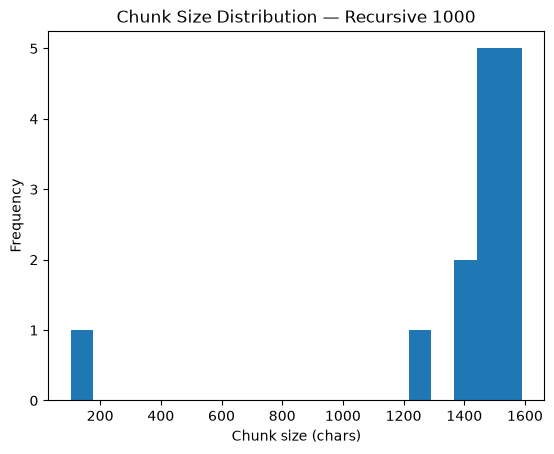

In [ ]:

#Plot chunk size distributions using matplotlib

import matplotlib.pyplot as plt

sizes = [len(chunk) for chunk in chunks]

plt.hist(sizes, bins=20)
plt.xlabel("Chunk size (chars)")
plt.ylabel("Frequency")
plt.title("Chunk Size Distribution — Recursive 1000")
plt.show()

In [60]:
def inspect_chunk_breaks(chunks, num_chunks=5, tail_length=50):
    """
    Prints the last characters of a few chunks to inspect where they break.
    Includes a basic heuristic to guess if it ends mid-sentence.
    """
    print(f"Inspecting the last {tail_length} characters of the first {num_chunks} chunks:\n")
    
    for i, chunk in enumerate(chunks[:num_chunks]):
        # Get the last 'tail_length' characters. 
        # We replace newlines with a symbol just to make it easier to read in the console.
        tail = chunk[-tail_length:].replace('\n', '\\n')
        
        # Simple heuristic: if the chunk doesn't end with standard sentence-ending 
        # punctuation (ignoring trailing spaces), it likely ends mid-sentence.
        ends_mid_sentence = not chunk.strip().endswith(('.', '!', '?', '"', '”'))
        
        print(f"--- Chunk {i + 1} ---")
        print(f"...{tail}")
        print(f"Ends mid-sentence (heuristic)? {'Yes' if ends_mid_sentence else 'No'}\n")

print("Inspecting Fixed-500 Strategy")
inspect_chunk_breaks(fixed_chunks)

print("\nInspecting Recursive-1000 Strategy")
inspect_chunk_breaks(recursive_chunks)

print("\nInspecting Token-500 Strategy")
inspect_chunk_breaks(token_chunks)



Inspecting Fixed-500 Strategy
Inspecting the last 50 characters of the first 5 chunks:

--- Chunk 1 ---
... necessarily agree with every single statement in 
Ends mid-sentence (heuristic)? Yes

--- Chunk 2 ---
...by the European Commission in June 2018. Contact N
Ends mid-sentence (heuristic)? Yes

--- Chunk 3 ---
...'s first draft, which was considered in the prepar
Ends mid-sentence (heuristic)? Yes

--- Chunk 4 ---
...he views expressed in this document reflect the op
Ends mid-sentence (heuristic)? Yes

--- Chunk 5 ---
...11/8 33/EU (OJ L 330, 14. 12.2011, p.39). For any 
Ends mid-sentence (heuristic)? Yes


Inspecting Recursive-1000 Strategy
Inspecting the last 50 characters of the first 5 chunks:

--- Chunk 1 ---
...AN COMMISSION ETHICS GUIDELINES FOR TRUSTWORTHY AI
Ends mid-sentence (heuristic)? Yes

--- Chunk 2 ---
...n 8 April 2019. A first draft of this document was
Ends mid-sentence (heuristic)? Yes

--- Chunk 3 ---
.... More information on the High -Level Expert Group
Ends m

## Chunking Strategy Trade-offs & Observations

### 1. Fixed-Size Chunking (`Fixed-500`)
* **Pros:** 
  * Simple and fast to execute.
  * Predictable chunk size across all datasets.
* **Cons:** 
  * Frequently cuts mid-word or mid-sentence, destroying semantic context.
  * Struggles with variable-length text structures (like natural transcripts).
* **Observed Impact:** Ends mid-sentence frequently, resulting in poor retrieval quality for RAG.

---

### 2. Recursive Character Chunking (`Recursive-1000`)
* **Pros:** 
  * Respects natural document boundaries (paragraphs, sentences, punctuation).
  * Keeps related semantic ideas together.
* **Cons:** 
  * Chunk sizes can vary significantly (high variance between min/max character lengths).
  * Does not guarantee exact token limits for LLM context windows.
* **Observed Impact:** Ideal for structured text like the PDF; rarely cuts mid-sentence.

---

### 3. Token-Based Chunking (`Token-500`)
* **Pros:** 
  * Guarantees exact token counts matching the `gpt-4o-mini` context constraints.
  * Optimal for controlling API costs and context window budgets.
* **Cons:** 
  * Token boundaries do not always align with sentence endings, leading to occasional mid-sentence cuts.
* **Observed Impact:** Great for LLM input predictability, but benefits from an overlap (e.g., 50 tokens) to preserve boundary context.

---

### Summary Recommendation
* **Use Case - Structured PDF:** `Recursive-1000` is preferred to maintain narrative flow and section integrity.
* **Use Case - Unstructured Transcript / LLM Context-Critical:** `Token-500` with overlapping windows ensures safe context boundaries without exceeding token limits.

# Analyze Chunk Quality

In [63]:
def pct_clean_boundaries(chunks):
    """
    Calculates the percentage of chunks that end with clean sentence punctuation (. ? !).
    Works with both plain strings and LangChain Document objects, while preventing 
    IndexError on empty strings and ZeroDivisionError on empty lists.
    """
    if not chunks:
        return 0.0

    valid_endings = ('.', '?', '!', '."', '?"', '!"')
    clean = 0

    for c in chunks:
        # Handles both plain strings and LangChain Document objects
        text = c.page_content if hasattr(c, "page_content") else c
        
        # .endswith() is safer than [-1] because it doesn't crash on empty strings
        if text.strip().endswith(valid_endings):
            clean += 1

    return (clean / len(chunks)) * 100

# Testing
print(f"Fixed-size: {pct_clean_boundaries(fixed_chunks):.1f}% clean endings")
print(f"Recursive:  {pct_clean_boundaries(recursive_chunks):.1f}% clean endings")
if "token_chunks" in locals():
    print(f"Token-500:  {pct_clean_boundaries(token_chunks):.1f}% clean endings")

Fixed-size: 2.1% clean endings
Recursive:  18.0% clean endings
Token-500:  4.1% clean endings
